# Atlas-DeePC: Gaussian Measurement Noise with $\lambda_g=0$

**100 paired environment seeds per noise level: 211--310.** The controller is the
current baseline: **48 physical charts, rank-60 uncentered linear-subspace bases,
iterative N=10 terminal selection, graph waypoints, and current-chart DeePC**.
The coefficient regularization is **$\lambda_g=0$**, instead of the baseline's
0.05. All other settings are fixed. There is no contextual rescue, filtering,
model fitting, IK, or noise-dependent controller retuning. The bounded SVD
coefficients and past-output slack penalty remain in place.

Gaussian measurement noise affects **both offline data and online observations**.
Success is evaluated against the **true simulator fingertip position**, never a
noisy sensor distance. All 320 steps are retained. These previously inspected
seeds form an exploratory paired ablation, not a new untouched test set.


In [1]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_deepc_mpl")
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/measurement_noise_ablation.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import measurement_noise_ablation as experiment
get_ipython().run_line_magic("matplotlib", "inline")
SEEDS = list(range(211, 311))
SD_RATIOS = [0.0, 0.01, 0.02, 0.05, 0.10]
RUN_EXPERIMENTS = False
WORKERS = 4
RESULT_ROOT = experiment.RESULT_ROOT
if RUN_EXPERIMENTS:
    experiment.run_all(SD_RATIOS, SEEDS, WORKERS)
payloads = {}
for ratio in SD_RATIOS:
    path = RESULT_ROOT / experiment.level_name(ratio) / "summary.json"
    assert path.exists(), f"Missing completed level {ratio}: enable RUN_EXPERIMENTS to run/resume."
    payload = json.loads(path.read_text())
    assert payload["version"] == experiment.VERSION and payload["seeds"] == SEEDS
    rows = payload["results"]
    assert len(rows) == 100 and {r["seed"] for r in rows} == set(SEEDS)
    assert all(r["steps"] == 320 and r["evaluation_uses_true_outputs"] for r in rows)
    assert all(r["candidate_count"] == 10 and r["clusters"] == 48 and r["svd_rank"] == 60 for r in rows)
    assert all(r["lam_g"] == 0 for r in rows)
    assert all(not r["noise_on_inputs"] and not r["feedback_fallback"] and not r["fitted_dynamics_model"] for r in rows)
    assert all(r["minimum_selected_goal_source_separation"] >= .06 for r in rows)
    payloads[ratio] = payload
clean_signature = payloads[0.0]["artifact"]["signature"]
for payload in payloads.values():
    signature = payload["artifact"]["signature"]
    for key in clean_signature:
        if key not in ("sd_ratio", "power_nsr"):
            assert signature[key] == clean_signature[key], key
frame = pd.DataFrame([r for payload in payloads.values() for r in payload["results"]])
frame["strict_success"] = frame.success_30 & frame.success_100
percent = 100*np.array(SD_RATIOS)
COLORS = ["#172238", "#0072B2", "#009E73", "#E69F00", "#D55E00"]
trace_errors = {}
error_rows = []
for row in frame.to_dict("records"):
    ratio, seed = row["noise_sd_ratio"], row["seed"]
    path = RESULT_ROOT / experiment.level_name(ratio) / f"seed{seed}_control_results.npz"
    with np.load(path, allow_pickle=True) as trace:
        error = 1000*trace["distance"]
    trace_errors[ratio, seed] = error
    tail = error[-100:]
    error_rows.append({"noise_sd_ratio": ratio, "seed": seed,
                       "tail_rmse_mm": np.sqrt(np.mean(tail**2)),
                       "tail_std_mm": np.std(tail), "tail_p95_mm": np.quantile(tail, .95),
                       "tail_within_10_pct": 100*np.mean(tail < 10),
                       "tail_within_20_pct": 100*np.mean(tail < 20)})
frame = frame.merge(pd.DataFrame(error_rows), on=["noise_sd_ratio", "seed"], validate="one_to_one")
print(f"Loaded {len(frame)} rollouts: five noise levels x 100 paired seeds.")
controls = pd.Series({"T_ini": 2, "T_f": 10, "steps": 320, "charts": 48,
    "rank": 60, "terminal candidates": 10, "q_xy": 100000, "q_joint": 5000,
    "q_dq": 20, "r": .0001, "lambda_g": 0, "lambda_ini": 100000,
    "lambda_delta_u": 5, "u_limit": 1, "coefficient bound scale": 3,
    "target latch (m)": .07, "solver": "CLARABEL"}, name="Value")
display(HTML("<details><summary>Fixed control parameters</summary>" + controls.to_frame().to_html() + "</details>"))


Loaded 500 rollouts: five noise levels x 100 paired seeds.


,Value
T_ini,2
T_f,10
steps,320
charts,48
rank,60
terminal candidates,10
q_xy,100000
q_joint,5000
q_dq,20
r,0.0001


## 1. Noise Definition and Placement

For channel $j$, let $s_j$ be its standard deviation across the **40,000 unique
clean offline measurements**, not repeated Hankel entries. Apply

$$\widetilde y_{t,j}=y_{t,j}+\epsilon_{t,j},\qquad
\epsilon_{t,j}\sim\mathcal N(0,\rho^2s_j^2).$$

$\rho$ is the **noise-SD / signal-SD ratio**. The equivalent **power NSR** is
$\rho^2$ relative to centered signal variance, and
$\mathrm{SNR}_{\mathrm{dB}}=-20\log_{10}\rho$. We report both conventions.
Online noise scales remain fixed from offline calibration; they do not depend on
the online trajectory, velocity, target, or observed tracking error.

- **Offline:** reconstruct 200 episodes of 200 samples, add one draw per time/channel,
  and rebuild overlapping windows. Every occurrence of the same physical sample
  receives the same noise. Applied inputs are unchanged. At nonzero levels, refit
  normalization, clustering, transition graph, medoid references, and SVD bases
  from noisy data. Zero noise uses the original clean atlas. Terminal candidates
  also come from the noisy library.
- **Online:** noise enters the existing output-map boundary, including reset and
  the two initialization samples. Localization, DeePC past matching, and the 7 cm
  latch all use noisy outputs. Each measurement is stored once in the history.
- **Exact quantities:** requested target and applied input commands. No process
  noise or actuator disturbance is introduced. Simulator truth is logged for
  post-run evaluation but never passed to the controller.

Noise is independent across the baseline's **ten lifted output channels**: four
joint cosine/sine channels, two angular velocities, fingertip x/y, and the two
augmented cosine/sine channels for $q_1+q_2$. Thus noisy periodic outputs need not
lie exactly on a unit circle. This is an output-space Gaussian model, not noise
on encoder angles before lifting; no projection or denoising is applied.

One offline noise realization is shared across seeds. Each environment seed has
an independent online stream. The same standard-normal draws are scaled across
levels (common random numbers). We do not average over independently recollected
noisy atlases. The original offline data and baseline artifacts are not overwritten.


In [2]:
calibration = []
for ratio, payload in payloads.items():
    sigma = np.asarray(payload["artifact"]["noise_std"])
    calibration.append({"Noise SD (%)": 100*ratio, "Power NSR": ratio**2,
                        "Power NSR (%)": 100*ratio**2,
                        "SNR (dB)": np.inf if ratio == 0 else -20*np.log10(ratio),
                        "Fingertip x noise SD (mm)": 1000*sigma[6],
                        "Fingertip y noise SD (mm)": 1000*sigma[7]})
display(pd.DataFrame(calibration).round(5))
scale = np.array(payloads[0.0]["artifact"]["signal_std"])
channels = pd.DataFrame({"Channel": experiment.CHANNELS,
                         "Unit": ["unitless"]*4 + ["rad/s"]*2 + ["m"]*2 + ["unitless"]*2,
                         "Offline signal SD": scale})
for ratio in SD_RATIOS[1:]:
    channels[f"Noise SD at {100*ratio:g}%"] = ratio*scale
display(HTML("<details><summary>Per-channel calibration</summary>" + channels.to_html(index=False) + "</details>"))


,Noise SD (%),Power NSR,Power NSR (%),SNR (dB),Fingertip x noise SD (mm),Fingertip y noise SD (mm)
0,0.0,0.0000,0.00,inf,0.00000,0.00000
1,1.0,0.0001,0.01,40.0000,1.00575,0.94178
2,2.0,0.0004,0.04,33.9794,2.01150,1.88356
3,5.0,0.0025,0.25,26.0206,5.02874,4.70890
4,10.0,0.0100,1.00,20.0000,10.05749,9.41780


Channel,Unit,Offline signal SD,Noise SD at 1%,Noise SD at 2%,Noise SD at 5%,Noise SD at 10%
cos(q1),unitless,0.716480,0.007165,0.014330,0.035824,0.071648
cos(q2),unitless,0.753868,0.007539,0.015077,0.037693,0.075387
sin(q1),unitless,0.694606,0.006946,0.013892,0.034730,0.069461
sin(q2),unitless,0.642360,0.006424,0.012847,0.032118,0.064236
dq1,rad/s,10.664104,0.106641,0.213282,0.533205,1.066410
dq2,rad/s,6.984419,0.069844,0.139688,0.349221,0.698442
fingertip x,m,0.100575,0.001006,0.002011,0.005029,0.010057
fingertip y,m,0.094178,0.000942,0.001884,0.004709,0.009418
cos(q1+q2),unitless,0.717119,0.007171,0.014342,0.035856,0.071712
sin(q1+q2),unitless,0.696239,0.006962,0.013925,0.034812,0.069624


## 2. True Tracking Accuracy and Success

Strict success requires **mean true error below 1 cm and maximum true error below
2 cm in both final-30 and final-100 windows**. The horizons, run length, QP weights,
input limits, coefficient-bound rule, and success thresholds are unchanged;
only coefficient regularization changes to zero.
Unsolved QPs retain the baseline's zero-action handling and are not discarded.


,Successes,Success rate (%),Median final-100 true error (mm),P90 final-100 true error (mm),Mean tail time below 10 mm (%),Unsolved QP steps
Noise SD (%),,,,,,
0.0,93,93.0,2.062,5.415,93.00,0
1.0,90,90.0,2.940,7.440,91.38,0
2.0,86,86.0,4.506,10.153,87.78,0
5.0,33,33.0,10.849,21.602,45.57,0
10.0,2,2.0,17.307,30.672,22.72,0


,Power NSR,Successes,Trials,Success rate (%),Median final-100 true error (mm),P90 final-100 true error (mm),Median tail RMSE (mm),Median within-seed tail SD (mm),Mean tail time below 10 mm (%),Mean tail time below 20 mm (%),Unsolved QP steps,Median goal-sample switches
Noise SD (%),,,,,,,,,,,,
0.0,0.000,93,100,93.0,2.062,5.415,2.071,0.000,93.00,98.00,0,0.0
1.0,0.000,90,100,90.0,2.940,7.440,3.008,0.797,91.38,96.54,0,0.0
2.0,0.000,86,100,86.0,4.506,10.153,4.841,1.181,87.78,94.14,0,0.0
5.0,0.003,33,100,33.0,10.849,21.602,11.277,2.819,45.57,84.27,0,0.0
10.0,0.010,2,100,2.0,17.307,30.672,18.298,6.782,22.72,61.83,0,3.0


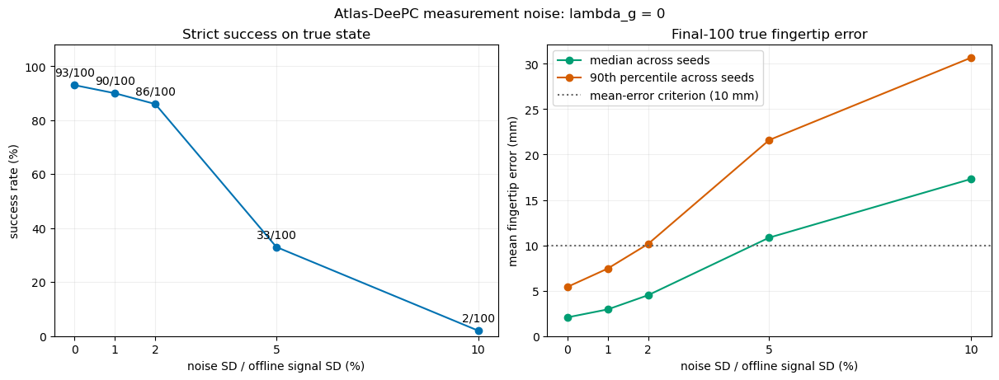

,Repaired,Regressed
Noise SD (%),,
1.0,4,7
2.0,3,10
5.0,1,61
10.0,0,91


,Repaired,Regressed,Repaired seeds,Regressed seeds
Noise SD (%),,,,
1.0,4,7,"[232, 247, 288, 296]","[234, 236, 251, 255, 274, 281, 283]"
2.0,3,10,"[232, 247, 288]","[222, 231, 236, 264, 277, 280, 282, 284, 293, 298]"
5.0,1,61,[288],"[211, 212, 213, 214, 216, 219, 222, 225, 228, 229, 230, 231, 234, 236, 237, 239, 242, 246, 248, 249, 251, 254, 255, 256, 257, 258, 260, 261, 262, 263, 264, 265, 267, 270, 272, 274, 275, 276, 277, 279, 280, 281, 283, 284, 285, 286, 287, 289, 290, 292, 293, 294, 297, 298, 300, 302, 303, 307, 308, 309, 310]"
10.0,0,91,[],"[211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 225, 226, 227, 228, 229, 230, 231, 233, 234, 235, 236, 237, 238, 239, 240, 242, 243, 244, 246, 248, 249, 250, 251, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 289, 290, 291, 292, 293, 294, 295, 297, 298, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310]"


In [3]:
summary_rows = []
for ratio in SD_RATIOS:
    rows = frame[frame.noise_sd_ratio == ratio]
    summary_rows.append({"Noise SD (%)": 100*ratio, "Power NSR": ratio**2,
                         "Successes": int(rows.strict_success.sum()), "Trials": len(rows),
                         "Success rate (%)": 100*rows.strict_success.mean(),
                         "Median final-100 true error (mm)": 1000*rows.mean_last_100.median(),
                         "P90 final-100 true error (mm)": 1000*rows.mean_last_100.quantile(.9),
                         "Median tail RMSE (mm)": rows.tail_rmse_mm.median(),
                         "Median within-seed tail SD (mm)": rows.tail_std_mm.median(),
                         "Mean tail time below 10 mm (%)": rows.tail_within_10_pct.mean(),
                         "Mean tail time below 20 mm (%)": rows.tail_within_20_pct.mean(),
                         "Unsolved QP steps": int(rows.unsolved_steps.sum()),
                         "Median goal-sample switches": rows.goal_sample_switches.median()})
summary = pd.DataFrame(summary_rows).set_index("Noise SD (%)")
display(summary[["Successes", "Success rate (%)", "Median final-100 true error (mm)",
                 "P90 final-100 true error (mm)", "Mean tail time below 10 mm (%)",
                 "Unsolved QP steps"]].round(3))
display(HTML("<details><summary>All error summary statistics</summary>" + summary.round(3).to_html() + "</details>"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
fig.suptitle("Atlas-DeePC measurement noise: lambda_g = 0")
axes[0].plot(percent, summary["Success rate (%)"], "o-", color="#0072B2")
for x, rate, count in zip(percent, summary["Success rate (%)"], summary.Successes):
    axes[0].annotate(f"{count}/100", (x, rate), xytext=(0, 8), textcoords="offset points", ha="center")
axes[0].set(ylim=(0, 108), title="Strict success on true state", ylabel="success rate (%)")
for column, color, label in [("Median final-100 true error (mm)", "#009E73", "median across seeds"),
                              ("P90 final-100 true error (mm)", "#D55E00", "90th percentile across seeds")]:
    axes[1].plot(percent, summary[column], "o-", color=color, label=label)
axes[1].axhline(10, color="#666666", linestyle=":", label="mean-error criterion (10 mm)")
axes[1].set(ylim=(0, None), title="Final-100 true fingertip error", ylabel="mean fingertip error (mm)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("noise SD / offline signal SD (%)")
    ax.set_xticks(percent)
    ax.grid(alpha=.2)
fig.savefig(RESULT_ROOT / "noise_success_and_accuracy.png", dpi=170)
plt.show()
(RESULT_ROOT / "noise_report.json").write_text(summary.reset_index().to_json(orient="records", indent=2))
clean = frame[frame.noise_sd_ratio == 0].set_index("seed")
paired = []
for ratio in SD_RATIOS[1:]:
    noisy = frame[frame.noise_sd_ratio == ratio].set_index("seed").loc[clean.index]
    repaired = noisy.index[noisy.strict_success & ~clean.strict_success].tolist()
    regressed = noisy.index[~noisy.strict_success & clean.strict_success].tolist()
    paired.append({"Noise SD (%)": 100*ratio, "Repaired": len(repaired), "Regressed": len(regressed),
                   "Repaired seeds": repaired, "Regressed seeds": regressed})
paired = pd.DataFrame(paired).set_index("Noise SD (%)")
display(paired[["Repaired", "Regressed"]])
display(HTML("<details><summary>Paired seed lists</summary>" + paired.to_html() + "</details>"))


### Error Distributions and Time Near the Target

Each seed contributes equally. The CDF shows the distribution of each seed's
**final-100 mean true fingertip error**, first over its complete range and then
zoomed to 0--30 mm. A CDF value at 10 mm is a mean-error pass fraction, **not**
the stricter success rate above.

The lower panels show every seed: the fraction of its final 100 steps below
10 mm, and the temporal standard deviation of its fingertip-error magnitude.
Low temporal SD alone does not imply accuracy: an arm stuck away from the target
can have constant error. Boxes show the median and interquartile range; whiskers
span the 5th--95th percentiles, and dots include all 100 seeds, including outliers.
These are empirical distributions, not confidence intervals.


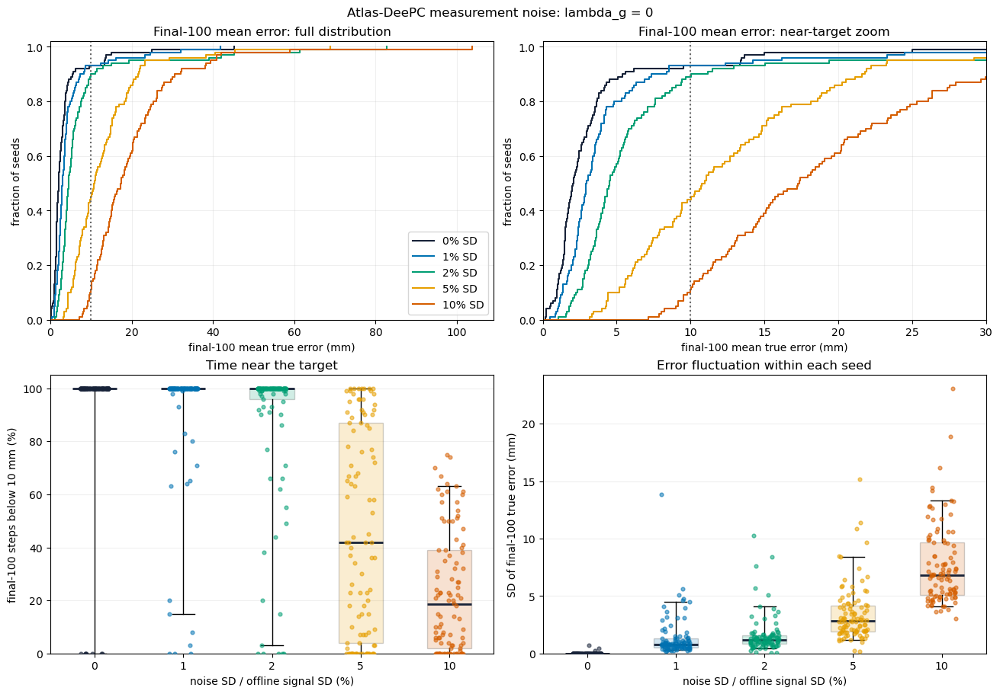

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle("Atlas-DeePC measurement noise: lambda_g = 0")
for ratio, color in zip(SD_RATIOS, COLORS):
    values = np.sort(1000*frame.loc[frame.noise_sd_ratio == ratio, "mean_last_100"].to_numpy())
    x = np.r_[0, values]
    cumulative = np.r_[0, np.arange(1, len(values)+1)/len(values)]
    for ax in axes[0]:
        ax.step(x, cumulative, where="post", color=color, label=f"{100*ratio:g}% SD")
for ax, title in zip(axes[0], ["Final-100 mean error: full distribution", "Final-100 mean error: near-target zoom"]):
    ax.axvline(10, color="#666666", linestyle=":")
    ax.set(xlim=(0, None), ylim=(0, 1.02), xlabel="final-100 mean true error (mm)",
           ylabel="fraction of seeds", title=title)
    ax.grid(alpha=.2)
axes[0, 1].set_xlim(0, 30)
axes[0, 0].legend(loc="lower right")
for ax, metric, title, ylabel in [
    (axes[1, 0], "tail_within_10_pct", "Time near the target", "final-100 steps below 10 mm (%)"),
    (axes[1, 1], "tail_std_mm", "Error fluctuation within each seed", "SD of final-100 true error (mm)")]:
    groups = [frame.loc[frame.noise_sd_ratio == r, metric].to_numpy() for r in SD_RATIOS]
    bp = ax.boxplot(groups, positions=np.arange(5), widths=.5, patch_artist=True, whis=(5, 95), showfliers=False,
                    medianprops={"color": "#172238", "linewidth": 2})
    jitter = np.random.default_rng(710).uniform(-.16, .16, 100)
    for i, (values, color, box) in enumerate(zip(groups, COLORS, bp["boxes"])):
        box.set(facecolor=color, alpha=.18)
        ax.scatter(i+jitter, values, s=12, color=color, alpha=.55, zorder=3)
    ax.set(ylim=(0, 105) if metric.endswith("pct") else (0, None),
           xlabel="noise SD / offline signal SD (%)", ylabel=ylabel, title=title)
    ax.set_xticks(np.arange(5), [f"{100*r:g}" for r in SD_RATIOS])
    ax.grid(axis="y", alpha=.2)
fig.savefig(RESULT_ROOT / "noise_error_distributions.png", dpi=170)
plt.show()


### Effect of Removing Coefficient Regularization

The previous $\lambda_g=0.05$ results are retained only for this paired check.
Noise draws, seed panel, and all other control settings are unchanged. This
comparison does not introduce tuning at individual noise levels.


In [5]:
regularization_rows = []
for ratio in SD_RATIOS:
    previous = json.loads((experiment.PREVIOUS_RESULT_ROOT / experiment.level_name(ratio) / "summary.json").read_text())
    old = pd.DataFrame(previous["results"]).set_index("seed").loc[SEEDS]
    new = frame[frame.noise_sd_ratio == ratio].set_index("seed").loc[SEEDS]
    old_config = dict(previous["artifact"]["signature"]["config"])
    new_config = dict(payloads[ratio]["artifact"]["signature"]["config"])
    assert old_config.pop("lam_g") == .05 and new_config.pop("lam_g") == 0
    assert old_config == new_config
    old_success = old.success_30 & old.success_100
    regularization_rows.append({"Noise SD (%)": 100*ratio,
        "Successes, lambda_g=0.05": int(old_success.sum()),
        "Successes, lambda_g=0": int(new.strict_success.sum()),
        "Median error, lambda_g=0.05 (mm)": 1000*old.mean_last_100.median(),
        "Median error, lambda_g=0 (mm)": 1000*new.mean_last_100.median(),
        "Median paired error change (mm)": 1000*(new.mean_last_100-old.mean_last_100).median(),
        "Seeds with lower mean error": int((new.mean_last_100 < old.mean_last_100).sum())})
regularization_comparison = pd.DataFrame(regularization_rows).set_index("Noise SD (%)")
display(regularization_comparison.round(3))
(RESULT_ROOT / "regularization_comparison.json").write_text(
    regularization_comparison.reset_index().to_json(orient="records", indent=2))


,"Successes, lambda_g=0.05","Successes, lambda_g=0","Median error, lambda_g=0.05 (mm)","Median error, lambda_g=0 (mm)",Median paired error change (mm),Seeds with lower mean error
Noise SD (%),,,,,,
0.0,93,93,2.062,2.062,-0.000,52
1.0,90,90,2.940,2.940,0.000,49
2.0,86,86,4.512,4.506,-0.001,64
5.0,33,33,10.849,10.849,-0.004,74
10.0,2,2,17.313,17.307,-0.003,78


1466

## 3. Integrity and Atlas Diagnostics

The zero-noise condition uses the same observer wrapper as the noisy conditions.
Its sensor outputs must exactly equal truth when noise is zero. Trajectories are
not expected to reproduce the previous baseline because $\lambda_g$ has changed.
We check that offline charts and bases are identical to the previous experiment
at each noise level and that the same sensor-noise draws are reused.


In [6]:
zero_matches = 0
for seed in SEEDS:
    zero_path = RESULT_ROOT / experiment.level_name(0) / f"seed{seed}_control_results.npz"
    with np.load(zero_path, allow_pickle=True) as zero:
        np.testing.assert_array_equal(zero["sensor_true"], zero["sensor_measured"])
        zero_matches += 1
atlas_rows = []
for ratio, payload in payloads.items():
    artifact = payload["artifact"]
    assert artifact["overlap_consistency_verified"] and artifact["applied_inputs_unchanged"]
    assert artifact["offline_unique_samples"] == 40000
    for name in ("chart_cache.npz", "behavioral_atlas.npz"):
        with np.load(RESULT_ROOT / experiment.level_name(ratio) / name, allow_pickle=True) as current:
            with np.load(experiment.PREVIOUS_RESULT_ROOT / experiment.level_name(ratio) / name, allow_pickle=True) as previous:
                assert current.files == previous.files
                for key in current.files:
                    if key != "config":
                        np.testing.assert_array_equal(current[key], previous[key])
    if ratio:
        np.testing.assert_allclose(artifact["empirical_offline_power_nsr"], ratio**2, rtol=.04)
    online_noise = []
    for row in payload["results"]:
        path = RESULT_ROOT / experiment.level_name(ratio) / f"seed{row['seed']}_control_results.npz"
        with np.load(path, allow_pickle=True) as trace:
            np.testing.assert_array_equal(trace["sensor_measured"][-320:], trace["y_measured"])
            np.testing.assert_array_equal(trace["sensor_true"][-320:], trace["y"])
            np.testing.assert_allclose(trace["distance"], np.linalg.norm(trace["y"][:, 6:8]-row["exact_target_xy"], axis=1))
            assert len(trace["sensor_true"]) == 323
            old_path = experiment.PREVIOUS_RESULT_ROOT / experiment.level_name(ratio) / path.name
            with np.load(old_path, allow_pickle=True) as old_trace:
                np.testing.assert_allclose(trace["sensor_measured"]-trace["sensor_true"],
                    old_trace["sensor_measured"]-old_trace["sensor_true"], rtol=0, atol=1e-14)
            online_noise.append(trace["sensor_measured"]-trace["sensor_true"])
    realized = np.sqrt(np.mean(np.concatenate(online_noise)**2, axis=0))/np.array(artifact["signal_std"])
    if ratio:
        np.testing.assert_allclose(realized, ratio, rtol=.03)
    else:
        np.testing.assert_array_equal(realized, np.zeros(10))
    sizes = artifact["chart_sizes"]
    atlas_rows.append({"Noise SD (%)": 100*ratio, "Charts": len(sizes), "Smallest chart": min(sizes),
                       "Largest chart": max(sizes), "Unreachable chart pairs": artifact["unreachable_chart_pairs"],
                       "Min observed online SD ratio (%)": 100*realized.min(),
                       "Max observed online SD ratio (%)": 100*realized.max(),
                       "Offline fit (s)": artifact["offline_preparation_s"]["chart_fit"],
                       "Offline bases/routes (s)": artifact["offline_preparation_s"]["svd_cache_and_routes"]})
print(f"Zero-noise sensor outputs exactly match truth for {zero_matches}/100 seeds.")
print("Charts and bases match the previous experiment; all 500 sensor-noise streams match within roundoff.")
display(pd.DataFrame(atlas_rows).set_index("Noise SD (%)").round(3))


Zero-noise sensor outputs exactly match truth for 100/100 seeds.
Charts and bases match the previous experiment; all 500 sensor-noise streams match within roundoff.


,Charts,Smallest chart,Largest chart,Unreachable chart pairs,Min observed online SD ratio (%),Max observed online SD ratio (%),Offline fit (s),Offline bases/routes (s)
Noise SD (%),,,,,,,,
0.0,48,558,1292,0,0.000,0.000,0.002,0.138
1.0,48,533,1653,0,0.992,1.008,0.124,0.190
2.0,48,583,1394,0,1.984,2.016,0.100,0.136
5.0,48,595,1379,0,4.961,5.040,0.109,0.166
10.0,48,472,1220,0,9.921,10.080,0.397,0.186


## 4. Computation Time

Local wall-clock timings use four rollout workers and one numerical-library thread
per worker. Five initial steps are excluded per rollout; there is no separate
warm-up. This shared-computer run is not an isolated hardware benchmark. The
existing control-loop timers exclude simulator stepping and sensor-noise generation.
QP time includes problem construction and solve. Chart fitting and SVD are offline.


mean_ms  median_ms   p99_ms
Noise SD (%) module                                                
0.0          QP construction and solve   36.931     34.584   76.327
             Total online control        37.055     34.704   76.646
1.0          QP construction and solve   35.462     33.710   65.958
             Total online control        35.577     33.820   66.080
2.0          QP construction and solve   50.625     35.878  212.772
             Total online control        50.798     35.995  213.267
5.0          QP construction and solve  113.554    111.619  400.630
             Total online control       113.936    112.004  402.755
10.0         QP construction and solve   50.426     38.844  180.847
             Total online control        50.604     38.977  181.292

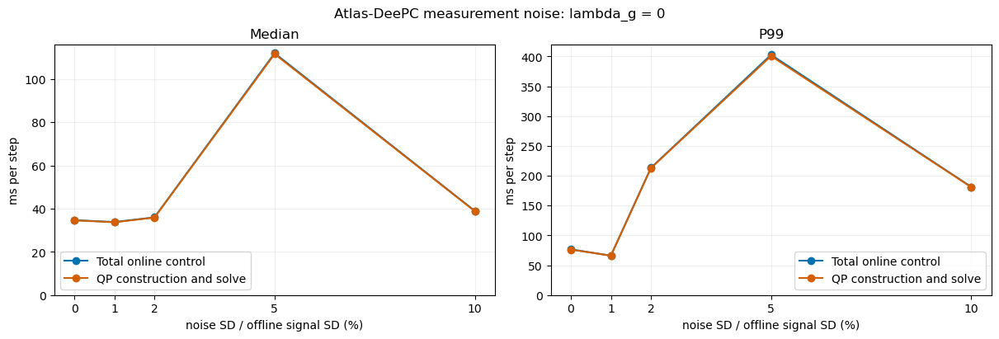

In [7]:
timing_rows = []
for ratio, payload in payloads.items():
    assert payload["timing"]["timed_steps"] == 31500
    timing_rows.extend({"Noise SD (%)": 100*ratio, **r} for r in payload["timing"]["modules"])
timing = pd.DataFrame(timing_rows)
display(timing[timing.module.isin(["Total online control", "QP construction and solve"])]
        .set_index(["Noise SD (%)", "module"])[["mean_ms", "median_ms", "p99_ms"]].round(3))
display(HTML("<details><summary>All computation modules</summary>" + timing.set_index(["Noise SD (%)", "module"])
             [["mean_ms", "median_ms", "p95_ms", "p99_ms"]].round(4).to_html() + "</details>"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
fig.suptitle("Atlas-DeePC measurement noise: lambda_g = 0")
for ax, metric, label in zip(axes, ["median_ms", "p99_ms"], ["Median", "P99"]):
    for module, color in [("Total online control", "#0072B2"), ("QP construction and solve", "#D55E00")]:
        rows = timing[timing.module == module]
        ax.plot(rows["Noise SD (%)"], rows[metric], "o-", label=module, color=color)
    ax.set(ylim=(0, None), xlabel="noise SD / offline signal SD (%)", ylabel="ms per step", title=label)
    ax.set_xticks(percent)
    ax.grid(alpha=.2)
    ax.legend()
fig.savefig(RESULT_ROOT / "noise_computation_time.png", dpi=170)
plt.show()


## 5. Twelve Seeds: Near-Target Error and Full Trajectories

Twelve fixed seeds are shown at every noise level, expanding the previous three
examples. They are fixed before completing this rerun, not chosen for favorable
outcomes. The first figure **zooms to 0--30 mm**, emphasizing the 10 mm criterion.
Small triangles at the upper boundary flag samples outside the zoom; they are
not substituted error values. The second figure retains the full vertical range.
The shaded final-100 window is the main evaluation period. All curves show true
fingertip error, with no smoothing or rollout truncation.


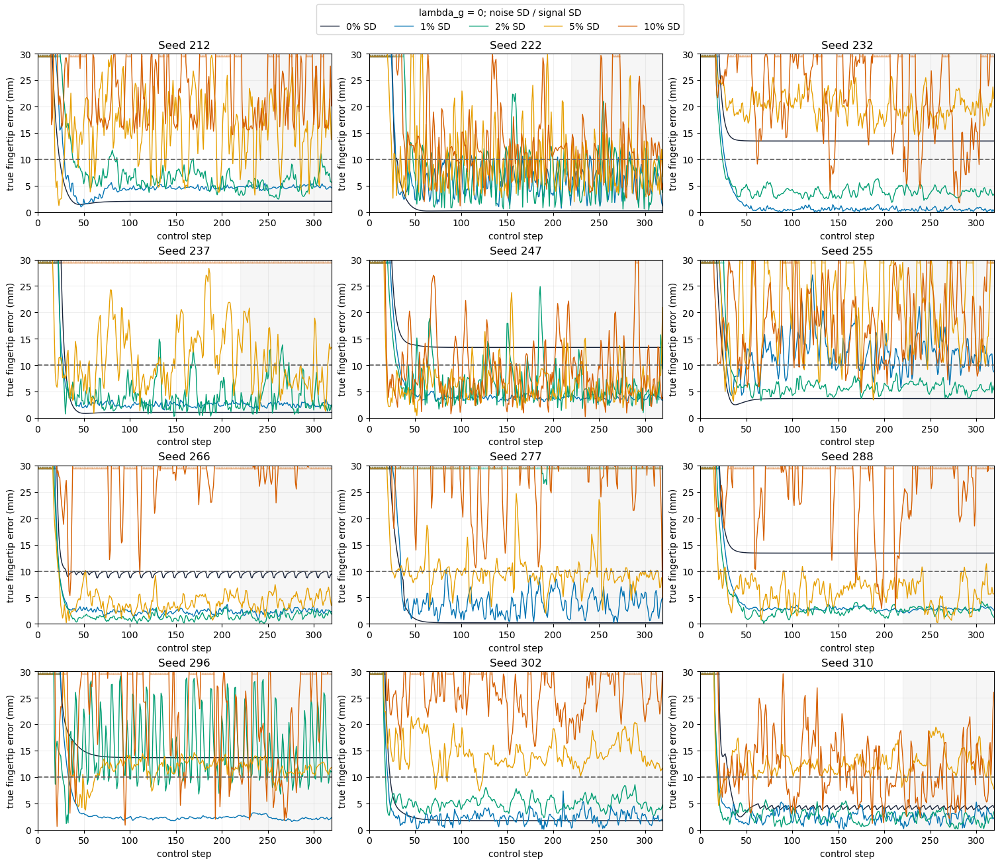

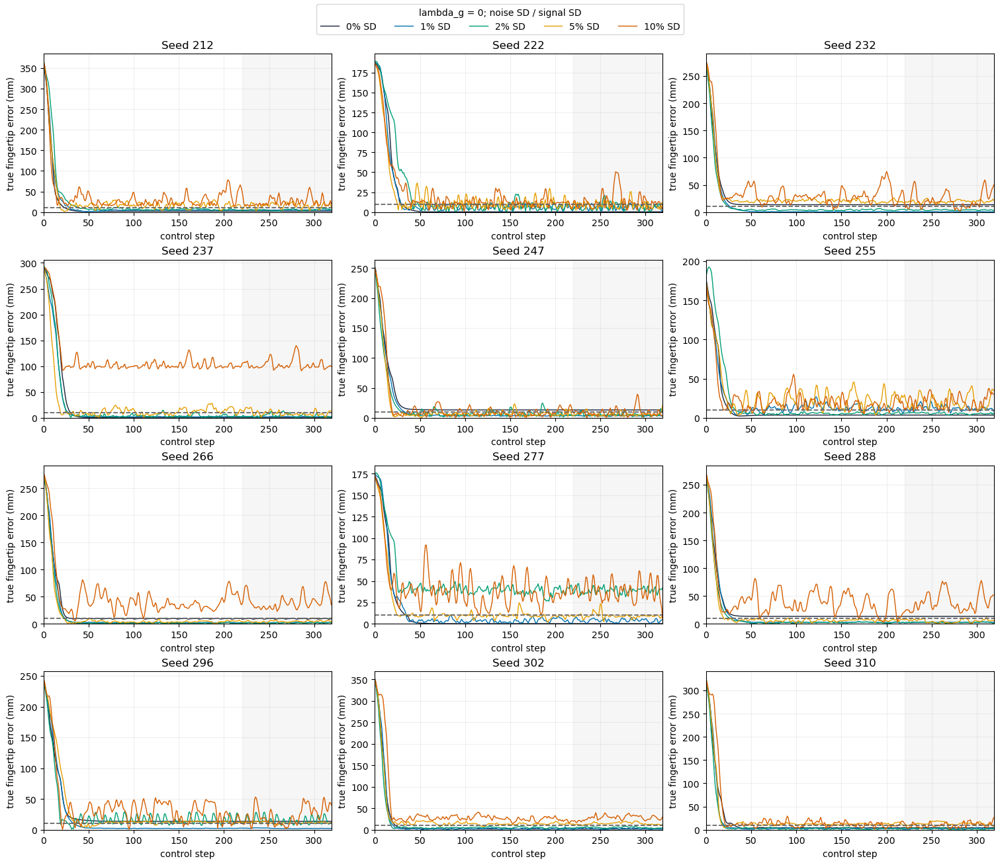

Noise SD (%),0.0,1.0,2.0,5.0,10.0
seed,,,,,
212,2.045,4.761,5.319,16.167,24.863
222,0.222,5.843,7.099,8.816,14.283
232,13.461,0.486,3.805,19.407,21.857
237,1.060,2.493,4.355,9.410,103.822
247,13.363,3.792,5.547,6.406,8.998
255,3.686,12.349,5.734,20.494,20.336
266,9.526,2.375,1.589,4.410,40.818
277,0.205,3.948,38.981,9.407,38.036
288,13.410,2.790,2.654,5.208,39.411


In [8]:
EXAMPLE_SEEDS = [212, 222, 232, 237, 247, 255, 266, 277, 288, 296, 302, 310]
for zoom in (True, False):
    fig, axes = plt.subplots(4, 3, figsize=(15, 13), constrained_layout=True)
    for ax, seed in zip(axes.flat, EXAMPLE_SEEDS):
        for ratio, color in zip(SD_RATIOS, COLORS):
            error = trace_errors[ratio, seed]
            ax.plot(error, color=color, label=f"{100*ratio:g}% SD", linewidth=1)
            if zoom:
                outside = np.flatnonzero(error > 30)
                ax.scatter(outside, np.full(len(outside), 29.6), marker="^", s=8,
                           color=color, alpha=.25, linewidths=0)
        ax.axvspan(220, 319, color="#666666", alpha=.06)
        ax.axhline(10, color="#666666", linestyle="--", linewidth=1.3)
        ax.set(ylim=(0, 30) if zoom else (0, None), xlim=(0, 319),
               xlabel="control step", ylabel="true fingertip error (mm)", title=f"Seed {seed}")
        if zoom:
            ax.set_yticks([0, 5, 10, 15, 20, 25, 30])
        ax.grid(alpha=.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=5,
               title="lambda_g = 0; noise SD / signal SD")
    suffix = "zoom" if zoom else "full"
    fig.savefig(RESULT_ROOT / f"noise_example_traces_{suffix}.png", dpi=150)
    plt.show()
example_table = frame[frame.seed.isin(EXAMPLE_SEEDS)].copy()
example_table["Final-100 mean true error (mm)"] = 1000*example_table.mean_last_100
example_table["Noise SD (%)"] = 100*example_table.noise_sd_ratio
display(example_table.pivot(index="seed", columns="Noise SD (%)",
                            values="Final-100 mean true error (mm)").round(3))


## 6. Paired Noisy-Rollout Videos

These six dashboards replay **saved $\lambda_g=0$ rollouts**, not new simulations:

- **Seed 212, 1% versus 5%:** successful low-noise tracking versus larger residual error.
- **Seed 222, 1% versus 5%:** a noisy failure whose final-100 mean remains below 10 mm;
  the strict test also requires maximum error below 20 mm in both tail windows.
- **Seed 237, 2% versus 10%:** successful tracking versus a large persistent offset.

The dark arm is simulator truth; the gray cross is the noisy fingertip reading.
The red error curve is true error, while the gray curve is sensed error. Reference
postures and chart routes use the matching noisy offline atlas. Noisy references
and predictions need not be kinematically consistent.

All **320 steps** remain visible, including late fluctuations. Playback uses the
same **0.25x dashboard-speed convention** as the earlier videos (relative to one
sample per frame at 20 fps, not simulator real time). Interpolation is for display
only; the controller did not smooth its measurements or actions. The error panel
zooms near the target; initial errors above its limit are outside that panel, but
their magnitude remains in the header and the full-range plots in Section 5.



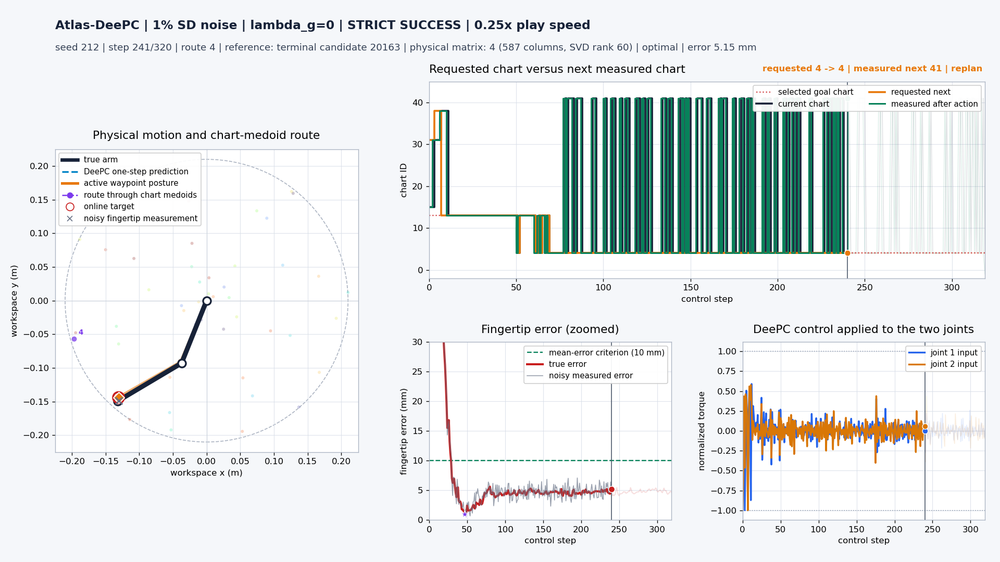
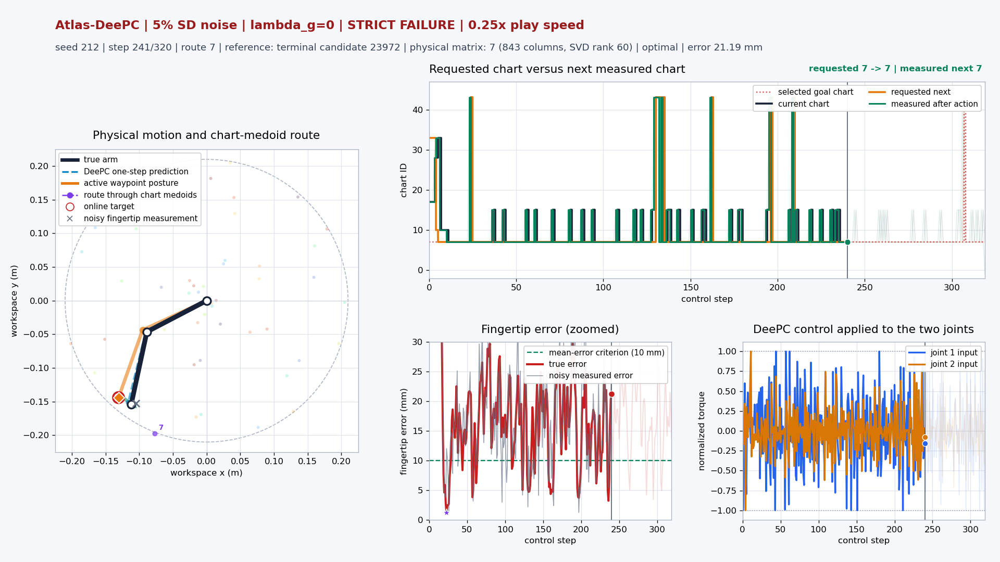


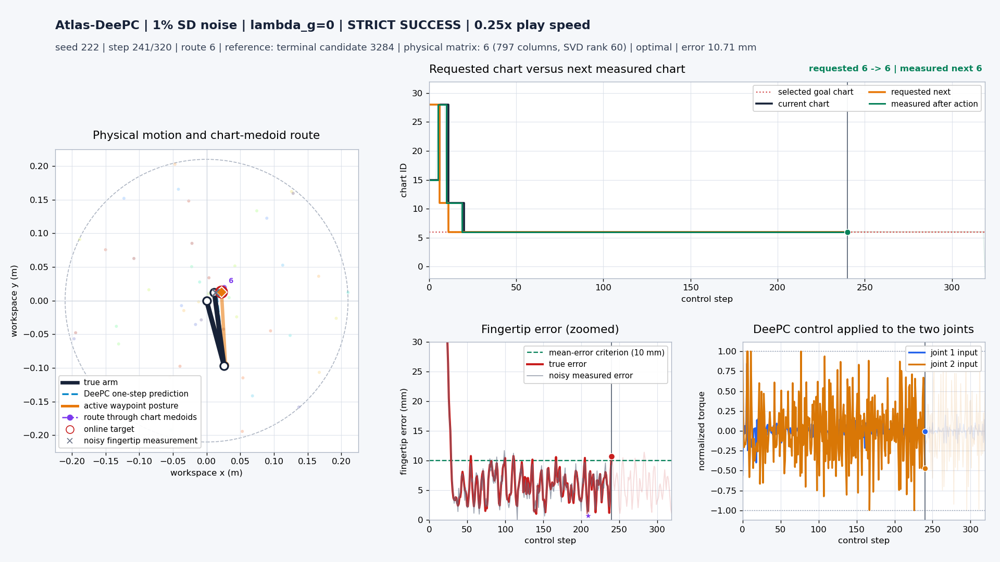
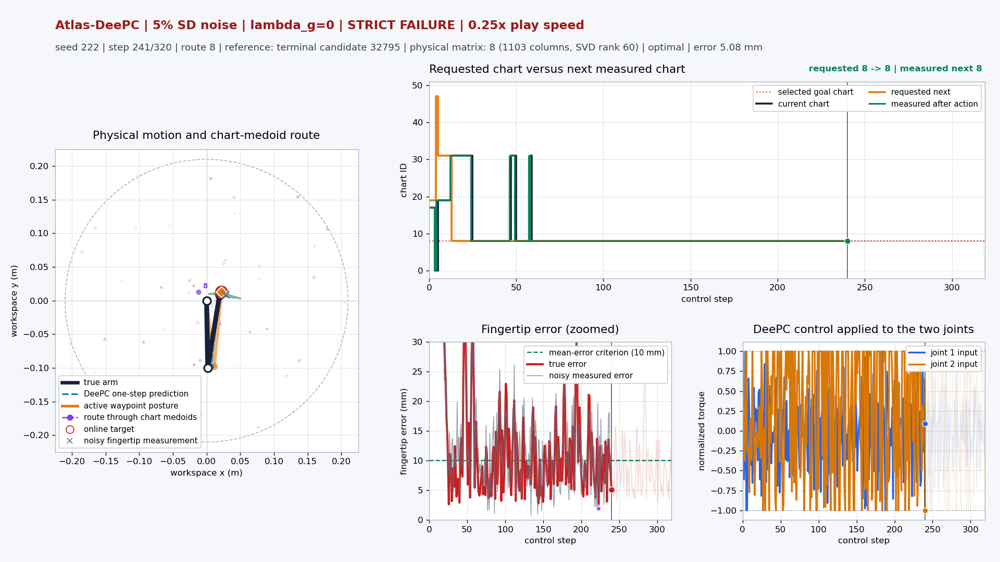


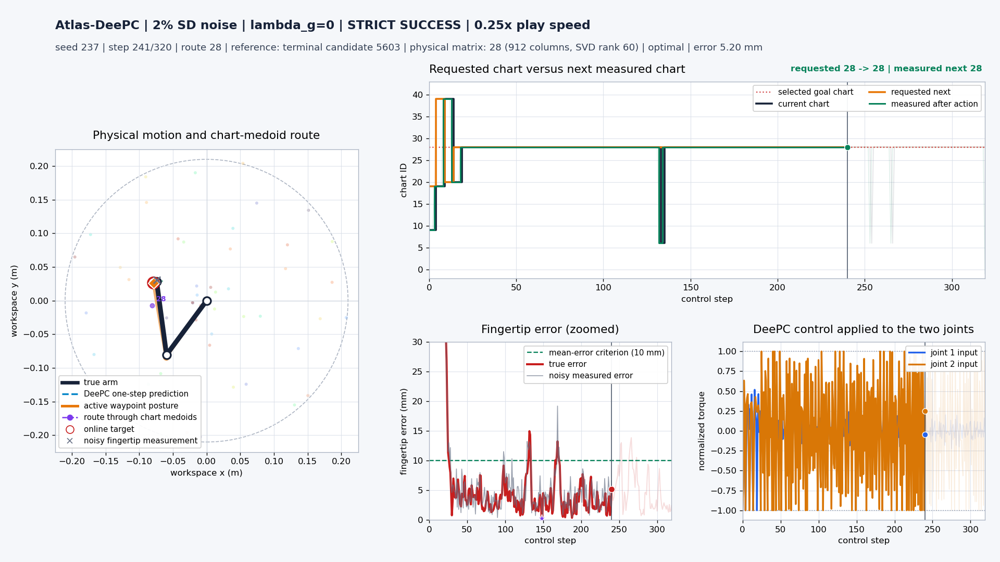
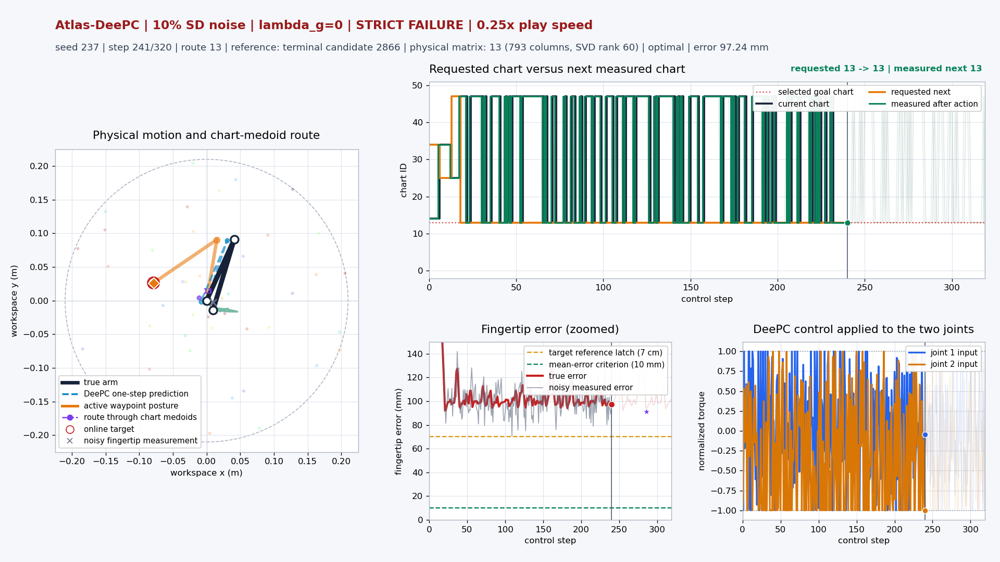

In [9]:
import base64
from candidate_goal_routing_experiment import file_digest
RENDER_VIDEOS = False
if RENDER_VIDEOS:
    from render_measurement_noise_videos import render_all
    render_all()
    get_ipython().run_line_magic("matplotlib", "inline")
VIDEO_DIR = RESULT_ROOT / "videos"
entries = json.loads((VIDEO_DIR / "manifest.json").read_text())
lookup = {(entry["seed"], entry["noise_sd_ratio"]): entry for entry in entries}
def noisy_video_card(seed, ratio):
    entry = lookup[seed, ratio]
    metadata = entry["metadata"]
    source_dir = RESULT_ROOT / experiment.level_name(ratio)
    source = source_dir / f"seed{seed}_control_results.npz"
    video = VIDEO_DIR / Path(entry["video"]).name
    poster = VIDEO_DIR / Path(entry["poster"]).name
    assert metadata["source_result_sha256"] == file_digest(source)
    assert metadata["source_atlas_sha256"] == file_digest(source_dir / "behavioral_atlas.npz")
    assert metadata["video_sha256"] == file_digest(video)
    assert metadata["poster_sha256"] == file_digest(poster)
    assert metadata["lam_g"] == 0 and metadata["noise_sd_ratio"] == ratio
    assert metadata["saved_control_steps"] == metadata["displayed_control_steps"] == 320
    assert metadata["true_arm_displayed"] and metadata["noisy_fingertip_displayed"]
    row = frame[(frame.seed == seed) & (frame.noise_sd_ratio == ratio)].iloc[0]
    outcome = "STRICT SUCCESS" if row.strict_success else "FAILED STRICT TEST"
    color = "#087443" if row.strict_success else "#B42318"
    mp4 = base64.b64encode(video.read_bytes()).decode("ascii")
    png = base64.b64encode(poster.read_bytes()).decode("ascii")
    return (f'<div style="min-width:0;background:white;color:#172238;padding:12px;border:1px solid #cbd5e1">'
        f'<h3 style="margin:0 0 8px;color:#172238">Seed {seed} | {100*ratio:g}% SD noise</h3>'
        f'<p style="margin:0 0 8px;color:{color}">{outcome}</p>'
        f'<p style="margin:0 0 8px;color:#344054">Final-100 true error: mean {1000*row.mean_last_100:.3f} mm; '
        f'maximum {1000*row.max_last_100:.3f} mm</p>'
        f'<video controls preload="none" style="width:100%" poster="data:image/png;base64,{png}" '
        f'src="data:video/mp4;base64,{mp4}"></video></div>')
for seed, lower, higher in ((212, .01, .05), (222, .01, .05), (237, .02, .10)):
    display(HTML('<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(min(100%,520px),1fr));gap:14px;margin-bottom:20px">'
                 + noisy_video_card(seed, lower) + noisy_video_card(seed, higher) + '</div>'))


## Reproduction and Scope

From the project root, using the existing environment:

```bash
python src/measurement_noise_ablation.py --workers 4
python src/render_measurement_noise_videos.py --workers 2
```

Completed levels/seeds are resumed; incompatible artifact settings are rejected.
The notebook defaults to reading saved results with coefficient regularization
zero. This override is local to the noise experiment; other baseline notebooks
are not changed. No duplicate full Hankel matrices
are saved: noise is regenerated deterministically, while atlases and reduced bases
are cached. Baseline data, notebooks, and results remain unchanged.

This combined ablation does not isolate offline versus online noise. It does not
establish robustness to correlated noise, sensor bias, encoder noise before output
lifting, process disturbances, or independently repeated offline datasets.
Noise also affects the posture retrieved for terminal-reference augmentation:
its fingertip entries are replaced with the exact target as in the baseline,
but its joint entries remain noisy. Consequently, results include reference
inconsistency as well as changes in localization and behavioral prediction.
